<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/practical_3_Tushar_Guleria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practical 3

Using the Student Rating Dataset and answer the following:

1. Calculate the percentage of visible minorities are tenure professors. Will you say that tenure status differed if teacher was a visible minority? [5]

2. Does average age differ by tenure? Produce the means and standard deviations for both tenured and untenured professors. [4]

3. Which graph works better and plot that graph for the age variable? [5]

4. Define the difference between pyplot.bar and pyplot.barh. Also plot the graph for gender variable. [4]

 5. What is the Median evaluation score for tenured Professors? [2]

Importing libraries

In [ ]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

loading the data


In [ ]:
df = pd.read_csv("/content/evals.csv")

Checking the data:

In [ ]:
df.head()

,score,rank,ethnicity,gender,language,age,cls_perc_eval,cls_did_eval,cls_students,cls_level,...,cls_credits,bty_f1lower,bty_f1upper,bty_f2upper,bty_m1lower,bty_m1upper,bty_m2upper,bty_avg,pic_outfit,pic_color
0,4.7,tenure track,minority,female,english,36,55.81395,24,43,upper,...,multi credit,5,7,6,2,4,6,5.0,not formal,color
1,4.1,tenure track,minority,female,english,36,68.80000,86,125,upper,...,multi credit,5,7,6,2,4,6,5.0,not formal,color
2,3.9,tenure track,minority,female,english,36,60.80000,76,125,upper,...,multi credit,5,7,6,2,4,6,5.0,not formal,color
3,4.8,tenure track,minority,female,english,36,62.60163,77,123,upper,...,multi credit,5,7,6,2,4,6,5.0,not formal,color
4,4.6,tenured,not minority,male,english,59,85.00000,17,20,upper,...,multi credit,4,4,2,2,3,3,3.0,not formal,color


1. Percentage of visible minorities who are tenured

In [ ]:
minority = df[df["ethnicity"] == "minority"]

tenured_minority = minority[minority["rank"] == "tenured"]

percentage = (len(tenured_minority) / len(minority)) * 100

print("Minority professors:", len(minority))
print("Tenured minority professors:", len(tenured_minority))
print("Percentage:", percentage)

Minority professors: 64
Tenured minority professors: 26
Percentage: 40.625


2. Does average age differ by tenure?

Create the two groups

In [ ]:
tenured = df[df["rank"] == "tenured"]

untenured = df[df["rank"] != "tenured"]

Calculate mean

In [ ]:
tenured_mean = tenured["age"].mean()
untenured_mean = untenured["age"].mean()

print("Tenured mean age:", tenured_mean)
print("Untenured mean age:", untenured_mean)

Tenured mean age: 51.88932806324111
Untenured mean age: 44.11904761904762


Calculate standard deviation

In [ ]:
tenured_sd = tenured["age"].std()
untenured_sd = untenured["age"].std()

print("Tenured SD:", tenured_sd)
print("Untenured SD:", untenured_sd)

Tenured SD: 8.654501807200475
Untenured SD: 9.43170460310381


In [ ]:
age_summary = df.assign(
    tenure_status=df["rank"].apply(
        lambda x: "Tenured" if x == "tenured" else "Untenured"
    )
).groupby("tenure_status")["age"].agg(["mean", "std", "count"])

print(age_summary)

                    mean       std  count
tenure_status                            
Tenured        51.889328  8.654502    253
Untenured      44.119048  9.431705    210


3. Which graph works better for the age variable?

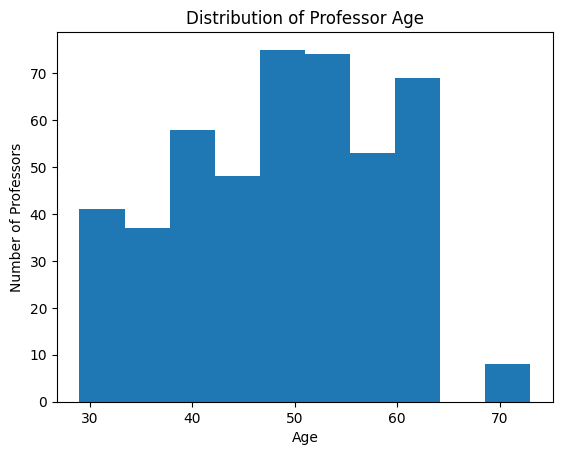

In [ ]:
plt.hist(df["age"], bins=10)

plt.xlabel("Age")
plt.ylabel("Number of Professors")
plt.title("Distribution of Professor Age")

plt.show()

4. Difference between pyplot.bar() and pyplot.barh()

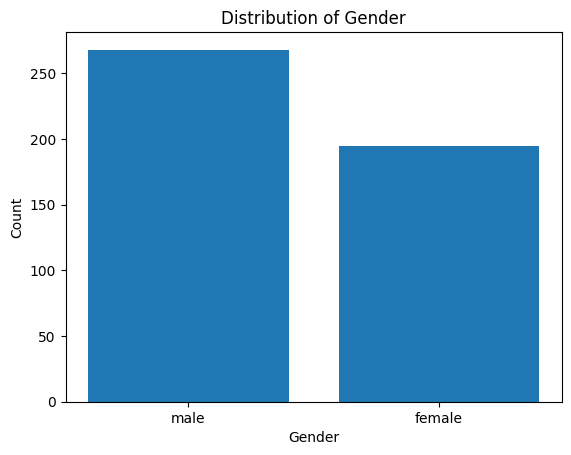

In [ ]:
gender_counts = df["gender"].value_counts()
x = gender_counts.index
y = gender_counts.values

plt.bar(x, y)
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Distribution of Gender")
plt.show()

Median evaluation score for tenured professors

In [ ]:
# ------------------------------------------------
# Q5. Median Evaluation Score for Tenured Professors
# ------------------------------------------------

tenured_scores = df[df["rank"] == "tenured"]["score"]

median_score = tenured_scores.median()

print("\nQ5")
print("Median evaluation score for tenured professors:",
      median_score)


Q5
Median evaluation score for tenured professors: 4.2
